# import libraries, data


In [ ]:
import pandas as pd
import numpy as np
# pd.set_option('display.max_columns', None)
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
data = pd.read_excel("/content/merged_data.xlsx")

# Exploratory data analysis of Merged data
From 7 different tables of Microsoft AdventureWorks sales data.

In [ ]:
data.describe()

,SalesOrderLineKey,ResellerKey,CustomerKey,ProductKey,OrderDateKey,DueDateKey,ShipDateKey,SalesTerritoryKey,Order Quantity,Unit Price,Extended Amount,Unit Price Discount Pct,Product Standard Cost,Total Product Cost,Sales Amount,Standard Cost,List Price,DateKey,Date,MonthKey
count,1.212530e+05,121253.000000,121253.000000,121253.000000,1.212530e+05,1.212530e+05,1.191400e+05,121253.000000,121253.000000,121253.000000,121253.000000,121253.0,121253.000000,121253.000000,121253.000000,121253.000000,121253.000000,1.191400e+05,119140,119140.000000
mean,5.782642e+07,170.043430,9384.833868,424.884094,2.019158e+07,2.019183e+07,2.019159e+07,5.410035,2.266138,465.180515,909.971564,0.0,362.643598,802.107230,905.621091,362.643598,619.342984,2.019159e+07,2019-08-09 08:50:43.411113216,201915.784430
min,4.365900e+07,-1.000000,-1.000000,212.000000,2.017070e+07,2.017071e+07,2.017071e+07,1.000000,1.000000,1.328200,1.374000,0.0,0.856500,0.856500,1.374000,0.856500,2.290000,2.017071e+07,2017-07-08 00:00:00,201707.000000
25%,4.987905e+07,-1.000000,-1.000000,339.000000,2.019041e+07,2.019042e+07,2.019041e+07,4.000000,1.000000,21.490000,24.990000,0.0,9.159300,10.842300,24.990000,9.159300,24.490000,2.019041e+07,2019-04-12 00:00:00,201904.000000
50%,5.702800e+07,3.000000,-1.000000,470.000000,2.019101e+07,2.019102e+07,2.019101e+07,6.000000,1.000000,49.990000,134.982000,0.0,38.492300,98.983600,134.982000,38.492300,63.500000,2.019101e+07,2019-10-12 00:00:00,201910.000000
75%,6.549000e+07,327.000000,18116.000000,528.000000,2.020022e+07,2.020030e+07,2.020022e+07,8.000000,3.000000,602.346000,1120.490000,0.0,486.706600,999.259500,1120.490000,486.706600,782.990000,2.020022e+07,2020-02-20 00:00:00,202002.000000
max,7.512300e+07,701.000000,29483.000000,606.000000,2.020062e+07,2.020062e+07,2.020062e+07,10.000000,44.000000,3578.270000,30992.910000,0.0,2171.294200,38530.385400,27893.619000,2171.294200,3578.270000,2.020062e+07,2020-06-15 00:00:00,202006.000000
std,9.009990e+06,224.536697,10171.582167,116.978898,7.981850e+03,8.021172e+03,7.990125e+03,2.835858,2.491806,752.041893,1705.565586,0.0,541.688873,1660.416044,1693.746343,541.688873,913.694200,7.990125e+03,NaN,79.904349


In [ ]:
data.describe(include='object')

,SKU,Product,Color,Model,Subcategory,Category,Customer ID,Customer,Customer City,Customer State-Province,...,Reseller City,Reseller State-Province,Reseller Country-Region,Reseller Postal Code,Channel,Sales Order,Sales Order Line,Region,Country,Group
count,121253,121253,87109,121253,121253,121253,121253,121253,121253,121253,...,121253,121253,121253,121253,121253,121253,121253,121253,121253,121253
unique,266,266,8,107,35,4,18485,18401,270,54,...,417,65,7,463,2,31455,121253,10,6,3
top,WB-H098,Water Bottle - 30 oz.,Black,Sport-100,Road Bikes,Accessories,[Not Applicable],[Not Applicable],[Not Applicable],[Not Applicable],...,[Not Applicable],[Not Applicable],[Not Applicable],[Not Applicable],Reseller,SO51721,SO43659 - 1,Southwest,United States,North America
freq,4688,4688,30064,9180,20918,41193,60855,60855,60855,60855,...,60398,60398,60398,60398,60855,72,1,25644,60153,79217


In [ ]:
categorical_features = data.select_dtypes(include=['object']).columns
categorical_features

Index(['SKU', 'Product', 'Color', 'Model', 'Subcategory', 'Category',
       'Customer ID', 'Customer', 'Customer City', 'Customer State-Province',
       'Customer Country-Region', 'Customer Postal Code', 'Fiscal Year',
       'Fiscal Quarter', 'Month', 'Full Date', 'Reseller ID', 'Business Type',
       'Reseller', 'Reseller City', 'Reseller State-Province',
       'Reseller Country-Region', 'Reseller Postal Code', 'Channel',
       'Sales Order', 'Sales Order Line', 'Region', 'Country', 'Group'],
      dtype='object')

In [ ]:
data.nunique()

# trying to understand wheather the features is categorical or not.

,0
SalesOrderLineKey,121253
ResellerKey,636
CustomerKey,18485
ProductKey,350
OrderDateKey,1081
DueDateKey,1081
ShipDateKey,1074
SalesTerritoryKey,10
Order Quantity,41
Unit Price,275


In [ ]:
# missing or outlier values in my data
data.isnull().sum()

# some order doesn't have ship date key two possibilities they never shipped or data not collected

,0
SalesOrderLineKey,0
ResellerKey,0
CustomerKey,0
ProductKey,0
OrderDateKey,0
DueDateKey,0
ShipDateKey,2113
SalesTerritoryKey,0
Order Quantity,0
Unit Price,0


In [ ]:
# fill null values from ShipDateKey
data['ShipDateKey'].fillna("Data not collected", inplace = True)
data['DateKey'].fillna("Data not collected", inplace = True)
data['Date'].fillna("Data not collected", inplace = True)
data['Fiscal Year'].fillna("Data not collected", inplace = True)
data['Fiscal Quarter'].fillna("Data not collected", inplace = True)
data['Month'].fillna("Data not collected", inplace = True)
data['Full Date'].fillna("Data not collected", inplace = True)
data['MonthKey'].fillna("Data not collected", inplace = True)


# fill na values of color column with unknown
data['Color'].fillna("unknown", inplace = True)

data.isnull().sum()

<ipython-input-8-a7daf5121ee7>:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  data['ShipDateKey'].fillna("Data not collected", inplace = True)
<ipython-input-8-a7daf5121ee7>:2: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'Data not collected' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  data['ShipDateKey'].fillna("Data not collected", inplace = True)
<ipython-input-8-a7daf5121ee7>:3: FutureWarning:

,0
SalesOrderLineKey,0
ResellerKey,0
CustomerKey,0
ProductKey,0
OrderDateKey,0
DueDateKey,0
ShipDateKey,0
SalesTerritoryKey,0
Order Quantity,0
Unit Price,0


In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 121253 entries, 0 to 121252
Data columns (total 49 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   SalesOrderLineKey        121253 non-null  int64  
 1   ResellerKey              121253 non-null  int64  
 2   CustomerKey              121253 non-null  int64  
 3   ProductKey               121253 non-null  int64  
 4   OrderDateKey             121253 non-null  int64  
 5   DueDateKey               121253 non-null  int64  
 6   ShipDateKey              121253 non-null  object 
 7   SalesTerritoryKey        121253 non-null  int64  
 8   Order Quantity           121253 non-null  int64  
 9   Unit Price               121253 non-null  float64
 10  Extended Amount          121253 non-null  float64
 11  Unit Price Discount Pct  121253 non-null  int64  
 12  Product Standard Cost    121253 non-null  float64
 13  Total Product Cost       121253 non-null  float64
 14  Sale

In [ ]:
# Calculate the correlation matrix
Numeric_features = data.select_dtypes(include=['int64', 'float64'])
corr_matrix = Numeric_features.corr()

corr_matrix


,SalesOrderLineKey,ResellerKey,CustomerKey,ProductKey,OrderDateKey,DueDateKey,SalesTerritoryKey,Order Quantity,Unit Price,Extended Amount,Unit Price Discount Pct,Product Standard Cost,Total Product Cost,Sales Amount,Standard Cost,List Price
SalesOrderLineKey,1.000000,-0.332146,0.422380,0.324203,0.894704,0.891983,0.163289,-0.215696,-0.220860,-0.237622,NaN,-0.264364,-0.226603,-0.237531,-0.264364,-0.272022
ResellerKey,-0.332146,1.000000,-0.702922,-0.073306,-0.255353,-0.259733,-0.220785,0.375159,-0.017903,0.191084,NaN,0.110558,0.237109,0.190171,0.110558,0.115053
CustomerKey,0.422380,-0.702922,1.000000,0.113997,0.330341,0.330454,0.257371,-0.468872,0.014020,-0.234462,NaN,-0.136852,-0.288873,-0.233728,-0.136852,-0.144152
ProductKey,0.324203,-0.073306,0.113997,1.000000,0.366339,0.368364,0.062638,-0.077612,-0.104415,-0.086438,NaN,-0.099435,-0.066629,-0.088111,-0.099435,-0.111860
OrderDateKey,0.894704,-0.255353,0.330341,0.366339,1.000000,0.985355,0.152849,-0.149648,-0.264082,-0.241623,NaN,-0.294308,-0.219830,-0.242117,-0.294308,-0.302170
DueDateKey,0.891983,-0.259733,0.330454,0.368364,0.985355,1.000000,0.153822,-0.151591,-0.263373,-0.242262,NaN,-0.294258,-0.220964,-0.242703,-0.294258,-0.302013
SalesTerritoryKey,0.163289,-0.220785,0.257371,0.062638,0.152849,0.153822,1.000000,-0.134821,0.041098,-0.075045,NaN,-0.018334,-0.098707,-0.075064,-0.018334,-0.023120
Order Quantity,-0.215696,0.375159,-0.468872,-0.077612,-0.149648,-0.151591,-0.134821,1.000000,-0.076946,0.308033,NaN,-0.014590,0.347217,0.304023,-0.014590,-0.012347
Unit Price,-0.220860,-0.017903,0.014020,-0.104415,-0.264082,-0.263373,0.041098,-0.076946,1.000000,0.642288,NaN,0.951365,0.514640,0.645849,0.951365,0.952198
Extended Amount,-0.237622,0.191084,-0.234462,-0.086438,-0.241623,-0.242262,-0.075045,0.308033,0.642288,1.000000,NaN,0.742258,0.977215,0.999352,0.742258,0.747534


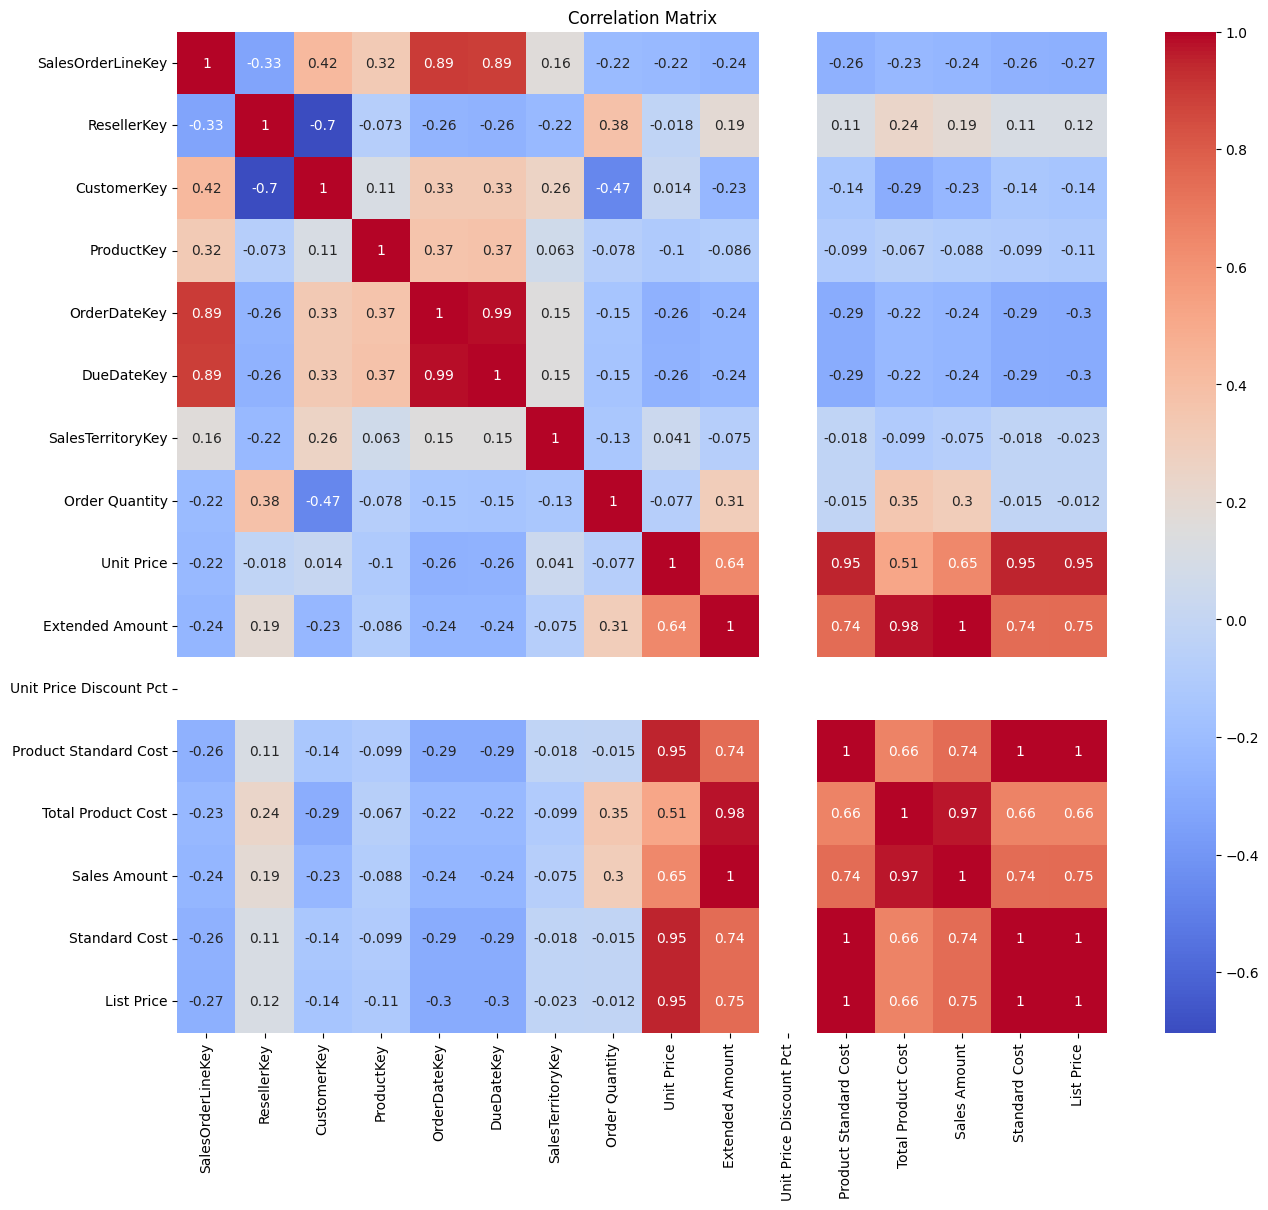

In [ ]:
plt.figure(figsize=(15, 13))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()

## categorical featues


In [ ]:
# Display summary statistics for numeric features
data.describe(include=['object'])



,ShipDateKey,SKU,Product,Color,Model,Subcategory,Category,Customer ID,Customer,Customer City,...,Reseller City,Reseller State-Province,Reseller Country-Region,Reseller Postal Code,Channel,Sales Order,Sales Order Line,Region,Country,Group
count,121253,121253,121253,121253,121253,121253,121253,121253,121253,121253,...,121253,121253,121253,121253,121253,121253,121253,121253,121253,121253
unique,1075,266,266,9,107,35,4,18485,18401,270,...,417,65,7,463,2,31455,121253,10,6,3
top,Data not collected,WB-H098,Water Bottle - 30 oz.,unknown,Sport-100,Road Bikes,Accessories,[Not Applicable],[Not Applicable],[Not Applicable],...,[Not Applicable],[Not Applicable],[Not Applicable],[Not Applicable],Reseller,SO51721,SO43659 - 1,Southwest,United States,North America
freq,2113,4688,4688,34144,9180,20918,41193,60855,60855,60855,...,60398,60398,60398,60398,60855,72,1,25644,60153,79217


## numerical features


In [ ]:

numeric_features = data.select_dtypes(include=['int64', 'float64'])
data.describe(include = [np.number])

,SalesOrderLineKey,ResellerKey,CustomerKey,ProductKey,OrderDateKey,DueDateKey,SalesTerritoryKey,Order Quantity,Unit Price,Extended Amount,Unit Price Discount Pct,Product Standard Cost,Total Product Cost,Sales Amount,Standard Cost,List Price
count,1.212530e+05,121253.000000,121253.000000,121253.000000,1.212530e+05,1.212530e+05,121253.000000,121253.000000,121253.000000,121253.000000,121253.0,121253.000000,121253.000000,121253.000000,121253.000000,121253.000000
mean,5.782642e+07,170.043430,9384.833868,424.884094,2.019158e+07,2.019183e+07,5.410035,2.266138,465.180515,909.971564,0.0,362.643598,802.107230,905.621091,362.643598,619.342984
std,9.009990e+06,224.536697,10171.582167,116.978898,7.981850e+03,8.021172e+03,2.835858,2.491806,752.041893,1705.565586,0.0,541.688873,1660.416044,1693.746343,541.688873,913.694200
min,4.365900e+07,-1.000000,-1.000000,212.000000,2.017070e+07,2.017071e+07,1.000000,1.000000,1.328200,1.374000,0.0,0.856500,0.856500,1.374000,0.856500,2.290000
25%,4.987905e+07,-1.000000,-1.000000,339.000000,2.019041e+07,2.019042e+07,4.000000,1.000000,21.490000,24.990000,0.0,9.159300,10.842300,24.990000,9.159300,24.490000
50%,5.702800e+07,3.000000,-1.000000,470.000000,2.019101e+07,2.019102e+07,6.000000,1.000000,49.990000,134.982000,0.0,38.492300,98.983600,134.982000,38.492300,63.500000
75%,6.549000e+07,327.000000,18116.000000,528.000000,2.020022e+07,2.020030e+07,8.000000,3.000000,602.346000,1120.490000,0.0,486.706600,999.259500,1120.490000,486.706600,782.990000
max,7.512300e+07,701.000000,29483.000000,606.000000,2.020062e+07,2.020062e+07,10.000000,44.000000,3578.270000,30992.910000,0.0,2171.294200,38530.385400,27893.619000,2171.294200,3578.270000


## datetime features

In [ ]:
data['Date']

,Date
0,2017-07-09 00:00:00
1,2017-07-09 00:00:00
2,2017-07-09 00:00:00
3,2017-07-09 00:00:00
4,2017-07-09 00:00:00
...,...
121248,Data not collected
121249,Data not collected
121250,Data not collected
121251,Data not collected


# **Product Affinity and cross-sell analysis**

**Product Affinity and cross-sell analysis**

Steps for Analysis

- Data Preprocessing:

  - Identify the columns representing orders (SalesOrderKey, SalesOrderLineKey) and products (ProductKey, Product).
  - Group orders to analyze combinations of products purchased together.
- Transaction Dataset Creation:

 - Create a transactional dataset where each row represents a unique order with all products in that order.
- Market Basket Analysis:

  - Use Association Rule Mining or Apriori Algorithm to identify frequently bought product combinations.
  - Calculate metrics such as support, confidence, and lift to understand relationships between products.

In [ ]:
import pandas as pd
from mlxtend.frequent_patterns import apriori, association_rules


In [ ]:
# Group products by order
transactions = data.groupby('Sales Order')['Product'].apply(list).reset_index()
transactions.head()


/usr/local/lib/python3.10/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


,Sales Order,Product
0,SO43659,"[Mountain-100 Black, 42, Mountain-100 Black, 4..."
1,SO43660,"[Road-650 Red, 44, Road-450 Red, 52]"
2,SO43661,"[HL Mountain Frame - Black, 48, HL Mountain Fr..."
3,SO43662,"[Road-650 Red, 52, Road-650 Black, 52, LL Road..."
4,SO43663,"[Road-650 Red, 60]"


In [ ]:
from mlxtend.preprocessing import TransactionEncoder

te = TransactionEncoder()
te_data = te.fit(transactions['Product']).transform(transactions['Product'])
df_encoded = pd.DataFrame(te_data, columns=te.columns_)


/usr/local/lib/python3.10/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


In [ ]:
# Generate frequent itemsets
frequent_itemsets = apriori(df_encoded, min_support=0.01, use_colnames=True)

# Generate association rules
rules = association_rules(frequent_itemsets, metric="lift", min_threshold=1, num_itemsets=len(frequent_itemsets))

rules = rules.sort_values(by=['confidence', 'lift'], ascending=False)
print(rules.head())


/usr/local/lib/python3.10/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


                                             antecedents  \
15770   (Classic Vest, S, AWC Logo Cap, Classic Vest, M)   
16220  (Hitch Rack - 4-Bike, AWC Logo Cap, Classic Ve...   
20236  (Hydration Pack - 70 oz., AWC Logo Cap, Hitch ...   
22846  (Bike Wash - Dissolver, Classic Vest, S, Class...   
25095  (Bike Wash - Dissolver, Classic Vest, S, Hydra...   

                                             consequents  antecedent support  \
15770  (Short-Sleeve Classic Jersey, XL, Short-Sleeve...            0.010332   
16220  (Short-Sleeve Classic Jersey, XL, Short-Sleeve...            0.010237   
20236  (Short-Sleeve Classic Jersey, XL, Short-Sleeve...            0.010078   
22846  (Short-Sleeve Classic Jersey, XL, Short-Sleeve...            0.010364   
25095  (Short-Sleeve Classic Jersey, XL, Short-Sleeve...            0.010173   

       consequent support   support  confidence       lift  representativity  \
15770            0.012049  0.010332         1.0  82.994723               1.0  

In [ ]:
rules.head()

/usr/local/lib/python3.10/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
15770,"(Classic Vest, S, AWC Logo Cap, Classic Vest, M)","(Short-Sleeve Classic Jersey, XL, Short-Sleeve...",0.010332,0.012049,0.010332,1.0,82.994723,1.0,0.010208,inf,0.998265,0.857520,1.0,0.928760
16220,"(Hitch Rack - 4-Bike, AWC Logo Cap, Classic Ve...","(Short-Sleeve Classic Jersey, XL, Short-Sleeve...",0.010237,0.012049,0.010237,1.0,82.994723,1.0,0.010114,inf,0.998169,0.849604,1.0,0.924802
20236,"(Hydration Pack - 70 oz., AWC Logo Cap, Hitch ...","(Short-Sleeve Classic Jersey, XL, Short-Sleeve...",0.010078,0.012049,0.010078,1.0,82.994723,1.0,0.009956,inf,0.998009,0.836412,1.0,0.918206
22846,"(Bike Wash - Dissolver, Classic Vest, S, Class...","(Short-Sleeve Classic Jersey, XL, Short-Sleeve...",0.010364,0.012049,0.010364,1.0,82.994723,1.0,0.010239,inf,0.998297,0.860158,1.0,0.930079
25095,"(Bike Wash - Dissolver, Classic Vest, S, Hydra...","(Short-Sleeve Classic Jersey, XL, Short-Sleeve...",0.010173,0.012049,0.010173,1.0,82.994723,1.0,0.010051,inf,0.998105,0.844327,1.0,0.922164


In [ ]:
rules.columns

/usr/local/lib/python3.10/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


Index(['antecedents', 'consequents', 'antecedent support',
       'consequent support', 'support', 'confidence', 'lift',
       'representativity', 'leverage', 'conviction', 'zhangs_metric',
       'jaccard', 'certainty', 'kulczynski'],
      dtype='object')

In [ ]:
rules.loc[:, ['antecedents', 'consequents']]

/usr/local/lib/python3.10/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


,antecedents,consequents
15770,"(Classic Vest, S, AWC Logo Cap, Classic Vest, M)","(Short-Sleeve Classic Jersey, XL, Short-Sleeve..."
16220,"(Hitch Rack - 4-Bike, AWC Logo Cap, Classic Ve...","(Short-Sleeve Classic Jersey, XL, Short-Sleeve..."
20236,"(Hydration Pack - 70 oz., AWC Logo Cap, Hitch ...","(Short-Sleeve Classic Jersey, XL, Short-Sleeve..."
22846,"(Bike Wash - Dissolver, Classic Vest, S, Class...","(Short-Sleeve Classic Jersey, XL, Short-Sleeve..."
25095,"(Bike Wash - Dissolver, Classic Vest, S, Hydra...","(Short-Sleeve Classic Jersey, XL, Short-Sleeve..."
...,...,...
159338,(Water Bottle - 30 oz.),"(Bike Wash - Dissolver, Long-Sleeve Logo Jerse..."
160359,(Water Bottle - 30 oz.),"(Bike Wash - Dissolver, Long-Sleeve Logo Jerse..."
165968,(Water Bottle - 30 oz.),"(Bike Wash - Dissolver, Long-Sleeve Logo Jerse..."
166478,(Water Bottle - 30 oz.),"(Bike Wash - Dissolver, Long-Sleeve Logo Jerse..."


`What does each column mean:`


In [ ]:
frequent_itemsets.tail()

/usr/local/lib/python3.10/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


,support,itemsets
3397,0.010014,"(Bike Wash - Dissolver, Long-Sleeve Logo Jerse..."
3398,0.010046,"(Bike Wash - Dissolver, Long-Sleeve Logo Jerse..."
3399,0.010014,"(Bike Wash - Dissolver, Long-Sleeve Logo Jerse..."
3400,0.010364,"(Bike Wash - Dissolver, Short-Sleeve Classic J..."
3401,0.010269,"(Bike Wash - Dissolver, Short-Sleeve Classic J..."


In [ ]:
frequent_itemsets['itemsets']

/usr/local/lib/python3.10/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


,itemsets
0,(AWC Logo Cap)
1,(Bike Wash - Dissolver)
2,"(Classic Vest, M)"
3,"(Classic Vest, S)"
4,(Fender Set - Mountain)
...,...
3397,"(Bike Wash - Dissolver, Long-Sleeve Logo Jerse..."
3398,"(Bike Wash - Dissolver, Long-Sleeve Logo Jerse..."
3399,"(Bike Wash - Dissolver, Long-Sleeve Logo Jerse..."
3400,"(Bike Wash - Dissolver, Short-Sleeve Classic J..."


### **Understanding the Results: Frequent Items Table and Rules Table**

#### **1. Frequent Items Table**  
This table provides insights into which products or combinations of products are commonly purchased together by customers. It has two key columns:  
- **Itemset**: Lists the individual product(s) or combinations of products.  
  - Example: `{Product A, Product B}` means these two products are often bought together.  
- **Support**: Represents the percentage of transactions where this product or product combination appears.  
  - Example: If the support for `{Product A, Product B}` is 0.10, it means 10% of all transactions include this combination.

**Business Insight**:  
The frequent items table helps you understand which products are popular or frequently bought together, allowing you to create product bundles or prioritize their availability in stock. For example, if customers often buy "bicycle tires" and "repair kits" together, you can bundle them as a package to boost sales.

---

#### **2. Rules Table**  
This table builds on the frequent items to show relationships between products. It tells us what happens when customers buy certain items. The key columns include:  
- **Antecedents**: The product(s) customers purchase first (e.g., `{Product A}`).  
- **Consequents**: The product(s) they tend to buy afterward (e.g., `{Product B}`).  
- **Support**: The percentage of transactions where both the antecedents and consequents appear together.  
- **Confidence**: The likelihood that customers who buy the antecedent will also buy the consequent. For instance, if confidence is 80%, 80% of people buying `{Product A}` also buy `{Product B}`.  
- **Lift**: How much more likely a customer is to buy the consequent when the antecedent is purchased, compared to random chance. A lift > 1 indicates a strong relationship.  
- **Conviction, Zhang’s Metric, and Other Metrics**: Additional metrics for advanced analysis of rule strength and reliability.

**Business Insight**:  
The rules table reveals actionable cross-selling opportunities. For example:  
- If the rule `{Bicycle Frame} → {Tires}` has high confidence (e.g., 75%) and lift (e.g., 2.5), it means customers who buy frames are highly likely to buy tires.  
- You can use this information to recommend tires to customers purchasing frames, either as a bundle or with a small discount to encourage sales.

---

#### **In Summary for Business Use**  
- The **frequent items table** shows which products or combinations are popular, helping with inventory planning and bundling decisions.  
- The **rules table** provides deeper insights into customer behavior, helping with cross-selling strategies by suggesting which products to recommend or discount together.  

This analysis enables data-driven decisions to improve customer satisfaction and increase revenue through strategic promotions and recommendations.

In [ ]:
# Here’s an explanation of each column in the results generated from the **association rules** using `mlxtend` or similar libraries:

# ---

# ### **1. `antecedents`**
# - The product(s) or item(s) in a basket that lead to the purchase of another product.
# - Example: `{Product A}` → `{Product B}` means Product A is the antecedent.

# ---

# ### **2. `consequents`**
# - The product(s) or item(s) that are likely to be purchased when the antecedent is present in a transaction.
# - Example: `{Product A}` → `{Product B}` means Product B is the consequent.

# ---

# ### **3. `antecedent support`**
# - The proportion of transactions that include the antecedent.
# - Formula:
#   \[
#   \text{antecedent support} = \frac{\text{Number of transactions with antecedents}}{\text{Total number of transactions}}
#   \]
# - Example: If Product A appears in 20% of transactions, its antecedent support is 0.2.

# ---

# ### **4. `consequent support`**
# - The proportion of transactions that include the consequent.
# - Formula:
#   \[
#   \text{consequent support} = \frac{\text{Number of transactions with consequents}}{\text{Total number of transactions}}
#   \]
# - Example: If Product B appears in 30% of transactions, its consequent support is 0.3.

# ---

# ### **5. `support`**
# - The proportion of transactions that contain both the antecedent and the consequent.
# - Formula:
#   \[
#   \text{support} = \frac{\text{Number of transactions with antecedent and consequent}}{\text{Total number of transactions}}
#   \]
# - Example: If both Product A and B appear together in 10% of transactions, the support is 0.1.

# ---

# ### **6. `confidence`**
# - The likelihood that the consequent is purchased given the antecedent is already in the basket.
# - Formula:
#   \[
#   \text{confidence} = \frac{\text{support}}{\text{antecedent support}}
#   \]
# - Example: If 10% of all transactions contain both Product A and B, but Product A appears in 20%, the confidence is \( \frac{0.1}{0.2} = 0.5 \).

# ---

# ### **7. `lift`**
# - The strength of the association between the antecedent and consequent compared to random chance.
# - Formula:
#   \[
#   \text{lift} = \frac{\text{confidence}}{\text{consequent support}}
#   \]
# - **Interpretation**:
#   - Lift > 1: Positive association (antecedents increase the likelihood of consequents).
#   - Lift = 1: No association.
#   - Lift < 1: Negative association (antecedents decrease the likelihood of consequents).

# ---

# ### **8. `representativity`**
# - Indicates how well the rule represents the dataset.
# - Formula:
#   \[
#   \text{representativity} = \text{support} \times \text{transactions containing antecedent}
#   \]
# - Helps understand how meaningful the association is for the overall dataset.

# ---

# ### **9. `leverage`**
# - Measures the difference between the observed support and the expected support if the antecedent and consequent were independent.
# - Formula:
#   \[
#   \text{leverage} = \text{support} - (\text{antecedent support} \times \text{consequent support})
#   \]
# - **Interpretation**:
#   - Positive leverage indicates a strong association.
#   - Zero leverage indicates independence.

# ---

# ### **10. `conviction`**
# - Measures how strongly the absence of the antecedent affects the absence of the consequent.
# - Formula:
#   \[
#   \text{conviction} = \frac{1 - \text{consequent support}}{1 - \text{confidence}}
#   \]
# - **Interpretation**:
#   - Higher conviction means stronger association.
#   - Conviction > 1 indicates positive association.

# ---

# ### **11. `zhangs_metric`**
# - A measure that combines confidence and lift to quantify association strength, minimizing the bias of rule direction.
# - Formula:
#   \[
#   \text{Zhang's Metric} = \frac{\text{support}}{\text{max(antecedent support, consequent support)}}
#   \]
# - Values range from 0 to 1, with higher values indicating stronger associations.

# ---

# ### **12. `jaccard`**
# - Measures the similarity between antecedents and consequents, based on their overlap in transactions.
# - Formula:
#   \[
#   \text{jaccard} = \frac{\text{support}}{\text{antecedent support} + \text{consequent support} - \text{support}}
#   \]
# - Higher values indicate more similarity or co-occurrence.

# ---

# ### **13. `certainty`**
# - Indicates how certain it is that the consequent will appear if the antecedent is present.
# - Related to confidence but adjusted for data distribution.

# ---

# ### **14. `kulczynski`**
# - Measures the symmetry of the relationship between antecedents and consequents.
# - Formula:
#   \[
#   \text{kulczynski} = \frac{\text{1}}{2} \left( \frac{\text{confidence(antecedent → consequent)}}{\text{confidence(consequent → antecedent)}} \right)
#   \]
# - Values close to 1 indicate symmetry (mutual association strength).

# ---

# ### **How to Use These Metrics**
# - **Support and Confidence**: Start by looking at rules with high support and confidence.
# - **Lift**: Focus on rules with lift > 1 for strong associations.
# - **Leverage**: Use to validate rules with higher-than-expected occurrence.
# - **Conviction and Zhang's Metric**: Use for nuanced rule ranking.



/usr/local/lib/python3.10/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)
